Quantos dias: 1460
Temperatura: de 6.1 até 95.0 °F
Consumo: de 1.37 até 3.01 GW


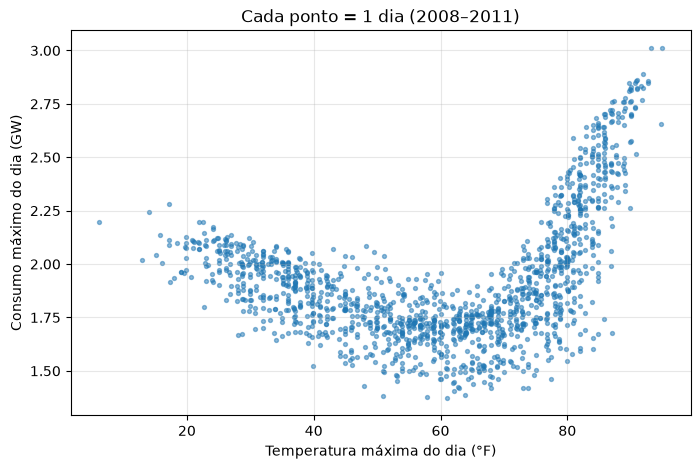

In [1]:
# --- Ferramentas ---
import numpy as np                 # numpy: a "calculadora" do Python para listas de números e matrizes
import matplotlib.pyplot as plt    # matplotlib: a ferramenta para desenhar gráficos

# --- Abrir as anotações do "caderno" ---
# --- Abrir as anotações do "caderno" ---
pasta = '../dados/ps1_data/'                          # a "gaveta" onde estão os arquivos
x = np.loadtxt(pasta + 'q5_max_temp.txt')    # junta: 'ps1_data/' + 'q5_max_temp.txt'
y = np.loadtxt(pasta + 'q5_max_demand.txt')

# --- Conferir o que temos ---
print('Quantos dias:', len(x))
print('Temperatura: de', x.min(), 'até', x.max(), '°F')
print('Consumo: de', round(y.min(), 2), 'até', round(y.max(), 2), 'GW')

# --- Desenhar: cada bolinha é um dia ---
plt.figure(figsize=(8, 5))
plt.scatter(x, y, s=8, alpha=0.5)    # s = tamanho da bolinha; alpha = transparência
plt.xlabel('Temperatura máxima do dia (°F)')
plt.ylabel('Consumo máximo do dia (GW)')
plt.title('Cada ponto = 1 dia (2008–2011)')
plt.grid(True, alpha=0.3)
plt.show()

Formato de Phi: (1460, 2)
Inclinação (θ1): 0.0051
Ponto de partida (θ2): 1.6097
Erro médio (ao quadrado): 0.0772


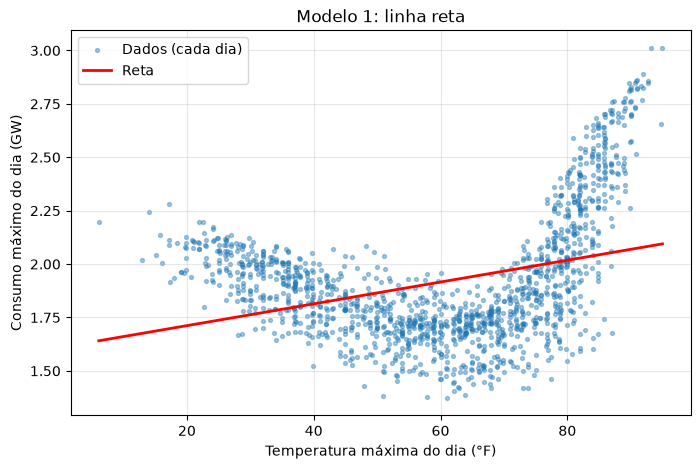

In [2]:
# --- 1. Montar a tabela Φ (Phi): uma linha por dia, duas colunas ---
m = len(x)                                  # número de dias (1460)
Phi = np.column_stack([x, np.ones(m)])      # coluna 1 = temperatura, coluna 2 = tudo 1
print('Formato de Phi:', Phi.shape)         # deve mostrar (1460, 2): 1460 linhas, 2 colunas

# --- 2. Aplicar a fórmula pronta (equações normais) ---
theta = np.linalg.solve(Phi.T @ Phi, Phi.T @ y)
print('Inclinação (θ1):', round(theta[0], 4))
print('Ponto de partida (θ2):', round(theta[1], 4))

# --- 3. Medir o erro: média dos erros ao quadrado ---
previsto = Phi @ theta                      # o que a reta "chuta" para cada dia
erro_reta = np.mean((previsto - y)**2)
print('Erro médio (ao quadrado):', round(erro_reta, 4))

# --- 4. Desenhar a reta por cima das bolinhas ---
x_linha = np.linspace(x.min(), x.max(), 200)       # 200 temperaturas igualmente espaçadas
y_linha = theta[0] * x_linha + theta[1]            # o que a reta prevê para cada uma

plt.figure(figsize=(8, 5))
plt.scatter(x, y, s=8, alpha=0.4, label='Dados (cada dia)')
plt.plot(x_linha, y_linha, color='red', linewidth=2, label='Reta')
plt.xlabel('Temperatura máxima do dia (°F)')
plt.ylabel('Consumo máximo do dia (GW)')
plt.title('Modelo 1: linha reta')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

Formato de Phi: (1460, 6)
Erro médio (ao quadrado): 0.0249


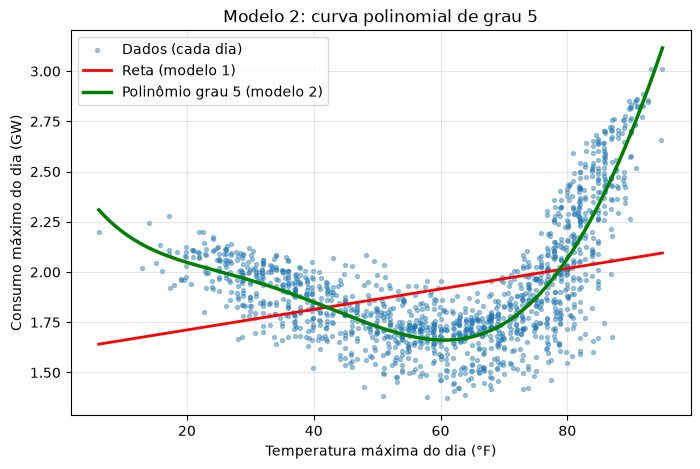

Grau 1 -> erro: 0.0772
Grau 2 -> erro: 0.0329
Grau 3 -> erro: 0.0252
Grau 4 -> erro: 0.025
Grau 5 -> erro: 0.0249


In [3]:
# --- Uma "receita" que monta a tabela Φ com potências ---
def tabela_polinomio(temp, grau):
    z = temp / 100                                   # troca de unidade: 95 °F vira 0.95
    colunas = [z**k for k in range(grau, -1, -1)]    # z^5, z^4, z^3, z^2, z^1, z^0 (=1)
    return np.column_stack(colunas)

# --- Montar Φ e aplicar a MESMA fórmula da reta ---
Phi_poli = tabela_polinomio(x, 5)
print('Formato de Phi:', Phi_poli.shape)            # (1460, 6): agora 6 colunas

theta_poli = np.linalg.solve(Phi_poli.T @ Phi_poli, Phi_poli.T @ y)
erro_poli = np.mean((Phi_poli @ theta_poli - y)**2)
print('Erro médio (ao quadrado):', round(erro_poli, 4))

# --- Desenhar ---
y_curva = tabela_polinomio(x_linha, 5) @ theta_poli   # previsão nas 200 temperaturas de desenho

plt.figure(figsize=(8, 5))
plt.scatter(x, y, s=8, alpha=0.4, label='Dados (cada dia)')
plt.plot(x_linha, y_linha, color='red', linewidth=2, label='Reta (modelo 1)')
plt.plot(x_linha, y_curva, color='green', linewidth=2.5, label='Polinômio grau 5 (modelo 2)')
plt.xlabel('Temperatura máxima do dia (°F)')
plt.ylabel('Consumo máximo do dia (GW)')
plt.title('Modelo 2: curva polinomial de grau 5')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

# --- Bônus: o que acontece com o erro conforme aumentamos o grau? ---
for g in range(1, 6):
    P = tabela_polinomio(x, g)
    t = np.linalg.solve(P.T @ P, P.T @ y)
    print('Grau', g, '-> erro:', round(np.mean((P @ t - y)**2), 4))

Grau | erro no caderno (treino) | erro na prova (dias novos)
   1 |     0.0746 |         0.0784
   2 |     0.0370 |         0.0346
   3 |     0.0226 |         0.0278
   5 |     0.0212 |         0.0308
   8 |     0.0184 |         0.0318
  12 |     0.0150 |         9.2495
  20 |     0.0116 |   9484976.0773


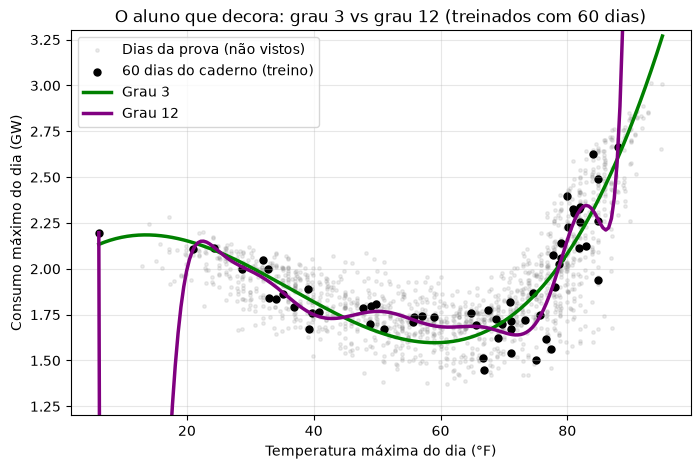

In [4]:
# --- Outra receita de tabela, com uma troca de unidade mais "centrada" ---
def tabela_poli2(temp, grau):
    z = (temp - 50) / 45            # leva as temperaturas para perto do intervalo -1 a +1
    return np.column_stack([z**k for k in range(grau, -1, -1)])

# --- Sortear 60 dias para o "caderno" (treino); o resto vira "prova" (teste) ---
rng = np.random.default_rng(0)       # sorteio "com semente": dá sempre o mesmo resultado
ordem = rng.permutation(len(x))      # embaralha os números 0..1459
treino = ordem[:60]                  # os 60 primeiros do embaralhamento
prova  = ordem[60:]                  # os outros 1400

print('Grau | erro no caderno (treino) | erro na prova (dias novos)')
for g in [1, 2, 3, 5, 8, 12, 20]:
    P = tabela_poli2(x[treino], g)
    t = np.linalg.lstsq(P, y[treino], rcond=None)[0]     # mesma conta de mínimos quadrados
    e_tr = np.mean((P @ t - y[treino])**2)
    e_pr = np.mean((tabela_poli2(x[prova], g) @ t - y[prova])**2)
    print(f'{g:4d} | {e_tr:10.4f} | {e_pr:14.4f}')

# --- Desenhar grau 3 vs grau 12, aprendendo só com os 60 dias ---
plt.figure(figsize=(8, 5))
plt.scatter(x[prova], y[prova], s=6, alpha=0.15, color='gray', label='Dias da prova (não vistos)')
plt.scatter(x[treino], y[treino], s=25, color='black', label='60 dias do caderno (treino)')
for g, cor in [(3, 'green'), (12, 'purple')]:
    t = np.linalg.lstsq(tabela_poli2(x[treino], g), y[treino], rcond=None)[0]
    plt.plot(x_linha, tabela_poli2(x_linha, g) @ t, color=cor, linewidth=2.5, label=f'Grau {g}')
plt.ylim(1.2, 3.3)
plt.xlabel('Temperatura máxima do dia (°F)')
plt.ylabel('Consumo máximo do dia (GW)')
plt.title('O aluno que decora: grau 3 vs grau 12 (treinados com 60 dias)')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

Centros dos sininhos (°F): [ 6.1 28.3 50.6 72.8 95. ]
Formato de Phi: (1460, 6)
Pesos (θ): [0.682 0.454 0.21  0.189 1.347 1.464]
Erro médio (ao quadrado): 0.0249


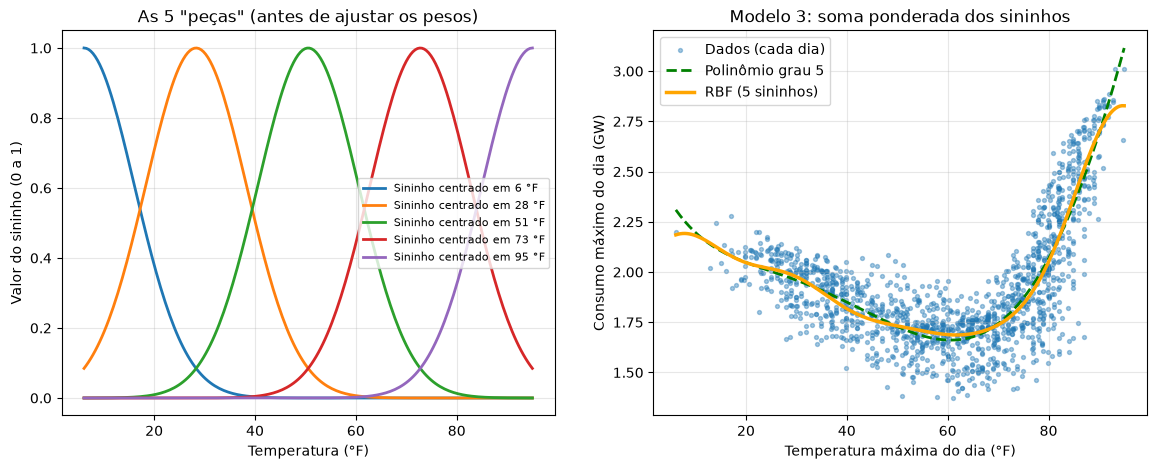

In [5]:
# --- Onde ficam os centros: 5 pontos igualmente espaçados de 6.1 a 95 °F ---
centros = np.linspace(x.min(), x.max(), 5)
sigma = 10                             # largura de cada sininho (pedido no PDF)
print('Centros dos sininhos (°F):', np.round(centros, 1))

# --- Receita da tabela Φ: uma coluna por sininho + coluna de 1 ---
def tabela_rbf(temp):
    colunas = [np.exp(-(temp - c)**2 / (2 * sigma**2)) for c in centros]
    colunas.append(np.ones(len(temp)))       # a velha coluna de 1 (ponto de partida)
    return np.column_stack(colunas)

# --- A MESMA fórmula de sempre ---
Phi_rbf = tabela_rbf(x)
print('Formato de Phi:', Phi_rbf.shape)
theta_rbf = np.linalg.solve(Phi_rbf.T @ Phi_rbf, Phi_rbf.T @ y)
print('Pesos (θ):', np.round(theta_rbf, 3))
erro_rbf = np.mean((Phi_rbf @ theta_rbf - y)**2)
print('Erro médio (ao quadrado):', round(erro_rbf, 4))

# --- Desenhar: à esquerda as peças, à direita o resultado ---
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

T = tabela_rbf(x_linha)
for j in range(5):
    ax1.plot(x_linha, T[:, j], linewidth=2, label=f'Sininho centrado em {centros[j]:.0f} °F')
ax1.set_xlabel('Temperatura (°F)')
ax1.set_ylabel('Valor do sininho (0 a 1)')
ax1.set_title('As 5 "peças" (antes de ajustar os pesos)')
ax1.legend(fontsize=8)
ax1.grid(True, alpha=0.3)

y_rbf = T @ theta_rbf
ax2.scatter(x, y, s=8, alpha=0.4, label='Dados (cada dia)')
ax2.plot(x_linha, y_curva, color='green', linewidth=2, linestyle='--', label='Polinômio grau 5')
ax2.plot(x_linha, y_rbf, color='orange', linewidth=2.5, label='RBF (5 sininhos)')
ax2.set_xlabel('Temperatura máxima do dia (°F)')
ax2.set_ylabel('Consumo máximo do dia (GW)')
ax2.set_title('Modelo 3: soma ponderada dos sininhos')
ax2.legend()
ax2.grid(True, alpha=0.3)
plt.show()

Formato de K: (1460, 1460)
Maior peso (em módulo): 8175.7
Erro médio (ao quadrado): 0.0247


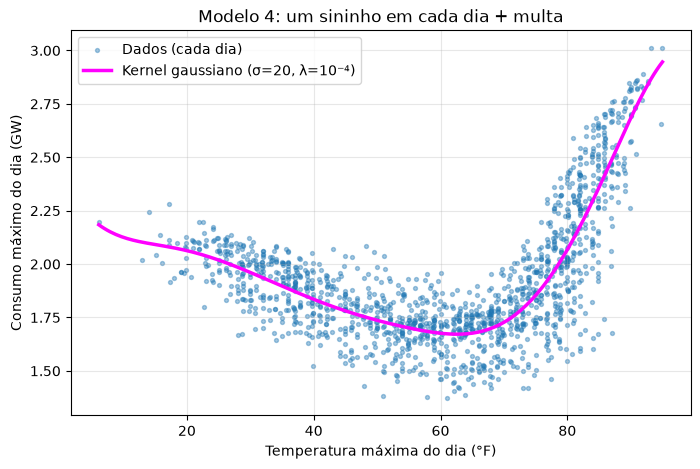


   λ     | erro   | maior peso
       0 | a conta quebrou: Singular matrix
   1e-08 | 0.0246 | 81416238.9
  0.0001 | 0.0247 | 8175.7
       1 | 0.0254 | 0.8
     100 | 0.1424 | 0.0


In [6]:
sigma = 20          # largura dos sininhos (pedido no PDF)
lam = 1e-4          # λ = 0.0001, a "multa" (1e-4 é como o Python escreve 10⁻⁴)

# --- Receita: tabela de "semelhança" entre duas listas de temperaturas ---
def sininhos_entre(a, b):
    dist2 = (a[:, None] - b[None, :])**2          # todas as distâncias² entre cada a e cada b
    return np.exp(-dist2 / (2 * sigma**2))         # o sininho de sempre

# --- Tabela K: cada dia comparado com cada dia ---
K = sininhos_entre(x, x)
print('Formato de K:', K.shape)                    # (1460, 1460)

# --- A fórmula do kernel: α = (K + λI)⁻¹ y ---
alpha = np.linalg.solve(K + lam * np.eye(len(x)), y)
print('Maior peso (em módulo):', round(np.abs(alpha).max(), 1))
erro_kernel = np.mean((K @ alpha - y)**2)
print('Erro médio (ao quadrado):', round(erro_kernel, 4))

# --- Desenhar: prever nas 200 temperaturas de desenho ---
y_kernel = sininhos_entre(x_linha, x) @ alpha

plt.figure(figsize=(8, 5))
plt.scatter(x, y, s=8, alpha=0.4, label='Dados (cada dia)')
plt.plot(x_linha, y_kernel, color='magenta', linewidth=2.5, label='Kernel gaussiano (σ=20, λ=10⁻⁴)')
plt.xlabel('Temperatura máxima do dia (°F)')
plt.ylabel('Consumo máximo do dia (GW)')
plt.title('Modelo 4: um sininho em cada dia + multa')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

# --- Experimento: o que a multa λ faz? ---
print('\n   λ     | erro   | maior peso')
for l in [0, 1e-8, 1e-4, 1, 100]:
    try:
        a = np.linalg.solve(K + l * np.eye(len(x)), y)
        print(f'{l:8g} | {np.mean((K @ a - y)**2):.4f} | {np.abs(a).max():.1f}')
    except Exception as erro:
        print(f'{l:8g} | a conta quebrou: {erro}')

In [7]:
# --- Garantir que o RBF está com σ = 20 (caso tenha ficado 3 ou 100 dos testes) ---
sigma = 20
Phi_rbf = tabela_rbf(x)
theta_rbf = np.linalg.solve(Phi_rbf.T @ Phi_rbf, Phi_rbf.T @ y)
y_rbf = tabela_rbf(x_linha) @ theta_rbf
erro_rbf = np.mean((Phi_rbf @ theta_rbf - y)**2)

# --- Refazer o kernel com λ = 1e-4 (o experimento mudou a variável 'a') ---
K = sininhos_entre(x, x)
alpha = np.linalg.solve(K + 1e-4 * np.eye(len(x)), y)
y_kernel = sininhos_entre(x_linha, x) @ alpha
erro_kernel = np.mean((K @ alpha - y)**2)

# --- Tabela de comparação ---
erro_media = np.mean((y - y.mean())**2)
print('Modelo                             | Erro médio² | RMSE (GW)')
print('-' * 62)
for nome, e in [('Chutar sempre a média', erro_media),
                ('1. Reta', erro_reta),
                ('2. Polinômio grau 5', erro_poli),
                ('3. RBF (5 sininhos, σ=20)', erro_rbf),
                ('4. Kernel gaussiano (σ=20, λ=1e-4)', erro_kernel)]:
    print(f'{nome:34s} | {e:11.4f} | {np.sqrt(e):.3f}')

# --- Gráfico 2x2 ---
fig, axes = plt.subplots(2, 2, figsize=(13, 9), sharex=True, sharey=True)
modelos = [('1. Linear (reta)', y_linha, 'red', erro_reta),
           ('2. Polinômio de grau 5', y_curva, 'green', erro_poli),
           ('3. RBF: 5 sininhos (σ = 20)', y_rbf, 'orange', erro_rbf),
           ('4. Kernel gaussiano (σ = 20, λ = 10⁻⁴)', y_kernel, 'magenta', erro_kernel)]

for ax, (titulo, curva, cor, e) in zip(axes.flat, modelos):
    ax.scatter(x, y, s=6, alpha=0.3, color='steelblue')
    ax.plot(x_linha, curva, color=cor, linewidth=2.5)
    ax.set_title(f'{titulo}\nerro médio² = {e:.4f}')
    ax.grid(True, alpha=0.3)
for ax in axes[1, :]:
    ax.set_xlabel('Temperatura máxima do dia (°F)')
for ax in axes[:, 0]:
    ax.set_ylabel('Consumo máximo do dia (GW)')

fig.suptitle('Item 5(a): pico de consumo vs. temperatura máxima — perda quadrática', fontsize=14)
plt.tight_layout()
plt.item5a_quatro_modelos.png', dpi=150, bbox_inches='tight')   # salva para os slides
plt.show()

SyntaxError: unterminated string literal (detected at line 44) (3137038350.py, line 44)

In [ ]:
%pip install cvxpy

   ---------------------------------------- 0.0/1.4 MB ? eta -:--:--
   ---------------------------------------- 0.0/1.4 MB ? eta -:--:--
   ---------------------------------------- 1.4/1.4 MB 6.7 MB/s  0:00:00
   ---------------------------------------- 0.0/655.1 kB ? eta -:--:--
   ---------------------------------------- 655.1/655.1 kB 12.7 MB/s  0:00:00
   ---------------------------------------- 0.0/887.3 kB ? eta -:--:--
   ---------------------------------------- 887.3/887.3 kB 41.7 MB/s  0:00:00
   ---------------------------------------- 0.0/2.7 MB ? eta -:--:--
   ---------------------------------------- 2.7/2.7 MB 15.7 MB/s  0:00:00
   ---------------------------------------- 0.0/7.6 MB ? eta -:--:--
   ---------------------------------------- 7.6/7.6 MB 47.2 MB/s  0:00:00

   ---- ----------------------------------- 1/9 [highspy]
   ------------- -------------------------- 3/9 [scs]
   ---------------------- ----------------- 5/9 [joblib]
   ---------------------- ---------


[notice] A new release of pip is available: 26.0.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


Modelo                    | Perda usada | erro médio absoluto | erro médio²
1. Reta                   | quadrado    |              0.2265 | 0.0772
1. Reta                   | absoluto    |              0.2193 | 0.0854
2. Polinômio grau 5       | quadrado    |              0.1204 | 0.0249
2. Polinômio grau 5       | absoluto    |              0.1192 | 0.0253
3. RBF (5 sininhos, σ=20) | quadrado    |              0.1215 | 0.0250
3. RBF (5 sininhos, σ=20) | absoluto    |              0.1200 | 0.0256


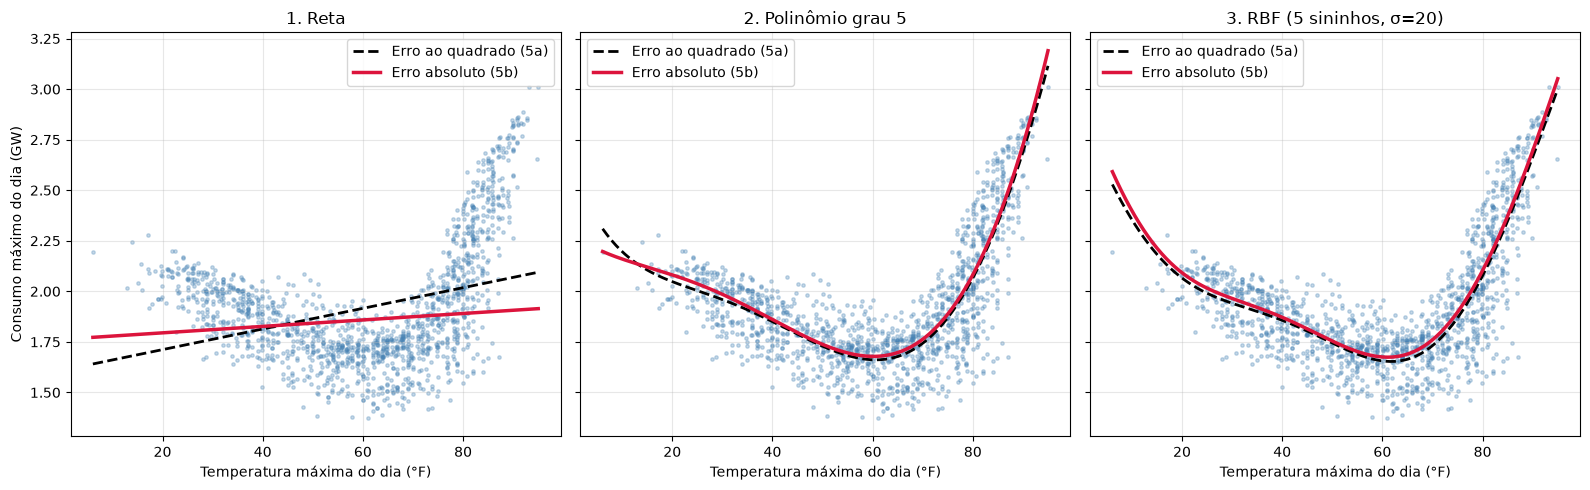

In [ ]:
import cvxpy as cp

# --- Receita da reta como "tabela", igual às outras ---
def tabela_reta(temp):
    return np.column_stack([temp, np.ones(len(temp))])

# --- 5(b): minimizar a SOMA DOS ERROS ABSOLUTOS ---
def ajustar_absoluto(Phi):
    theta = cp.Variable(Phi.shape[1])                    # as letras desconhecidas
    erro_total = cp.sum(cp.abs(Phi @ theta - y))         # soma dos |erros|, escrito como se fala
    cp.Problem(cp.Minimize(erro_total)).solve()          # "minimize isso" (ele monta os tetos sozinho)
    return theta.value

# --- 5(a): a fórmula pronta de antes, para comparar ---
def ajustar_quadrado(Phi):
    return np.linalg.solve(Phi.T @ Phi, Phi.T @ y)

modelos = [('1. Reta', tabela_reta),
           ('2. Polinômio grau 5', lambda t: tabela_polinomio(t, 5)),
           ('3. RBF (5 sininhos, σ=20)', tabela_rbf)]
sigma = 20

fig, axes = plt.subplots(1, 3, figsize=(16, 5), sharey=True)
print('Modelo                    | Perda usada | erro médio absoluto | erro médio²')
for ax, (nome, tabela) in zip(axes, modelos):
    Phi = tabela(x)
    t_q = ajustar_quadrado(Phi)
    t_a = ajustar_absoluto(Phi)
    for rotulo, t in [('quadrado', t_q), ('absoluto', t_a)]:
        e = Phi @ t - y
        print(f'{nome:25s} | {rotulo:11s} | {np.mean(np.abs(e)):19.4f} | {np.mean(e**2):.4f}')

    ax.scatter(x, y, s=6, alpha=0.3, color='steelblue')
    ax.plot(x_linha, tabela(x_linha) @ t_q, color='black', linewidth=2, linestyle='--', label='Erro ao quadrado (5a)')
    ax.plot(x_linha, tabela(x_linha) @ t_a, color='crimson', linewidth=2.5, label='Erro absoluto (5b)')
    ax.set_title(nome)
    ax.set_xlabel('Temperatura máxima do dia (°F)')
    ax.legend()
    ax.grid(True, alpha=0.3)
axes[0].set_ylabel('Consumo máximo do dia (GW)')
plt.tight_layout()
plt.savefig('../figuras/item5b_absoluto_vs_quadrado.png', dpi=150, bbox_inches='tight')
plt.show()

Temperaturas diferentes: 479
Tempo para resolver: 9 segundos
Modelo               | Perda usada | erro médio absoluto | erro médio²
4. Kernel gaussiano  | quadrado    |              0.1198 | 0.0247
4. Kernel gaussiano  | absoluto    |              0.1182 | 0.0251


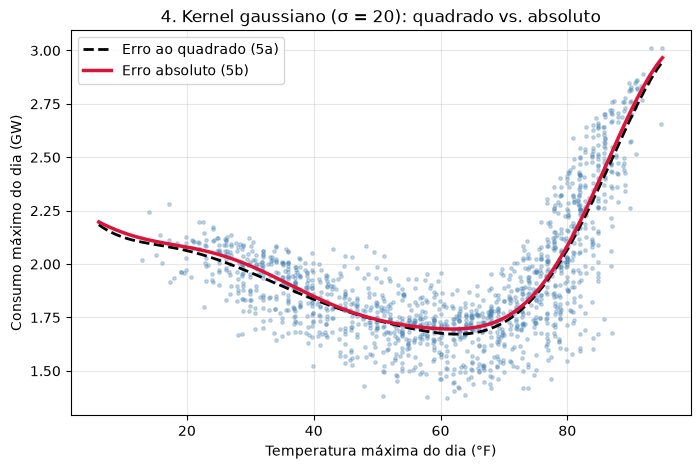

In [ ]:
import time

sigma = 20

# --- 5(a), para comparar: igual a antes ---
K = sininhos_entre(x, x)
alpha_q = np.linalg.solve(K + 1e-4 * np.eye(len(x)), y)

# --- 5(b): um sininho por TEMPERATURA DIFERENTE (479) em vez de um por dia (1460) ---
centros_k = np.unique(x)                      # lista das temperaturas sem repetição
print('Temperaturas diferentes:', len(centros_k))
K2 = sininhos_entre(x, centros_k)             # tabela 1460 dias x 479 sininhos

inicio = time.time()
alpha = cp.Variable(len(centros_k))
erro_total = cp.sum(cp.abs(K2 @ alpha - y))   # soma dos |erros| (um erro por dia, como sempre)
multa = 1e-6 * cp.sum_squares(alpha)          # a multa minúscula pedida no PDF
cp.Problem(cp.Minimize(erro_total + multa)).solve(solver=cp.SCS)
alpha_a = alpha.value
print(f'Tempo para resolver: {time.time() - inicio:.0f} segundos')

# --- Comparar as duas réguas ---
print('Modelo               | Perda usada | erro médio absoluto | erro médio²')
for rotulo, e in [('quadrado', K @ alpha_q - y), ('absoluto', K2 @ alpha_a - y)]:
    print(f'4. Kernel gaussiano  | {rotulo:11s} | {np.mean(np.abs(e)):19.4f} | {np.mean(e**2):.4f}')

# --- Desenhar ---
plt.figure(figsize=(8, 5))
plt.scatter(x, y, s=6, alpha=0.3, color='steelblue')
plt.plot(x_linha, sininhos_entre(x_linha, x) @ alpha_q, color='black', linewidth=2,
         linestyle='--', label='Erro ao quadrado (5a)')
plt.plot(x_linha, sininhos_entre(x_linha, centros_k) @ alpha_a, color='crimson', linewidth=2.5,
         label='Erro absoluto (5b)')
plt.xlabel('Temperatura máxima do dia (°F)')
plt.ylabel('Consumo máximo do dia (GW)')
plt.title('4. Kernel gaussiano (σ = 20): quadrado vs. absoluto')
plt.legend()
plt.grid(True, alpha=0.3)
plt.savefig('../figuras/item5b_kernel.png', dpi=150, bbox_inches='tight')
plt.show()